# 🎯 PRML Project: Human Activity Recognition (HAR)
## *Exploratory Data Analysis — Comprehensive Laboratory Report*

---

### 📋 Project & Dataset Metadata
| Parameter | Details |
|---|---|
| **Course** | Pattern Recognition & Machine Learning (PRML) |
| **Dataset** | UCI Human Activity Recognition with Smartphones (Kaggle Edition) |
| **Samples** | 10,299 instances (Train: 7,352 / Test: 2,947) |
| **Dimensionality** | 561 Features (Time & Frequency Domain Accelerometer + Gyroscope) |
| **Target Classes** | 6 Categorical Activity Labels |
| **Class Balance** | Well-Distributed (Range: ~980 to 1,400 per class) |
| **Missing Values** | 0 (Zero Missing, Zero Null Entries) |

---

### 🏃 Target Activities Under Analysis
1. **WALKING** (Dynamic locomotion)
2. **WALKING_UPSTAIRS** (Vertical dynamic locomotion)
3. **WALKING_DOWNSTAIRS** (Deceleration dynamic locomotion)
4. **SITTING** (Static posture)
5. **STANDING** (Static upright posture)
6. **LAYING** (Static horizontal posture)

---

## 1️⃣ System Setup & Data Import

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

warnings.filterwarnings('ignore')
os.makedirs('../presentation', exist_ok=True)

# Premium visual styling
plt.style.use('seaborn-v0_8-whitegrid')
palette = {
    'WALKING': '#1f77b4',
    'WALKING_UPSTAIRS': '#ff7f0e',
    'WALKING_DOWNSTAIRS': '#2ca02c',
    'SITTING': '#d62728',
    'STANDING': '#9467bd',
    'LAYING': '#8c564b'
}

train_df = pd.read_csv('../data/train.csv')
test_df = pd.read_csv('../data/test.csv')

print(f"✅ Train Partition Loaded: {train_df.shape[0]:,} rows x {train_df.shape[1]} columns")
print(f"✅ Test Partition Loaded:  {test_df.shape[0]:,} rows x {test_df.shape[1]} columns")
print(f"✅ Total Unified Dataset:  {len(train_df) + len(test_df):,} samples")

✅ Train Partition Loaded: 7,352 rows x 563 columns
✅ Test Partition Loaded:  2,947 rows x 563 columns
✅ Total Unified Dataset:  10,299 samples


## 2️⃣ Data Hygiene & Missing Value Verification

In [2]:
null_train = train_df.isnull().sum().sum()
null_test = test_df.isnull().sum().sum()
dups_train = train_df.duplicated().sum()
dups_test = test_df.duplicated().sum()

print("=" * 50)
print("🔍 DATA INTEGRITY AUDIT")
print("=" * 50)
print(f"Missing Values (Train) : {null_train}")
print(f"Missing Values (Test)  : {null_test}")
print(f"Duplicate Rows (Train) : {dups_train}")
print(f"Duplicate Rows (Test)  : {dups_test}")
print("Status: Pristine tabular dataset requiring no imputation.")

🔍 DATA INTEGRITY AUDIT
Missing Values (Train) : 0
Missing Values (Test)  : 0
Duplicate Rows (Train) : 0
Duplicate Rows (Test)  : 0
Status: Pristine tabular dataset requiring no imputation.


## 3️⃣ Target Distribution & Class Equilibrium Analysis

                    Train Samples  Train (%)  Test Samples  Test (%)
Activity                                                            
LAYING                       1407      19.14           537     18.22
SITTING                      1286      17.49           491     16.66
STANDING                     1374      18.69           532     18.05
WALKING                      1226      16.68           496     16.83
WALKING_DOWNSTAIRS            986      13.41           420     14.25
WALKING_UPSTAIRS             1073      14.59           471     15.98


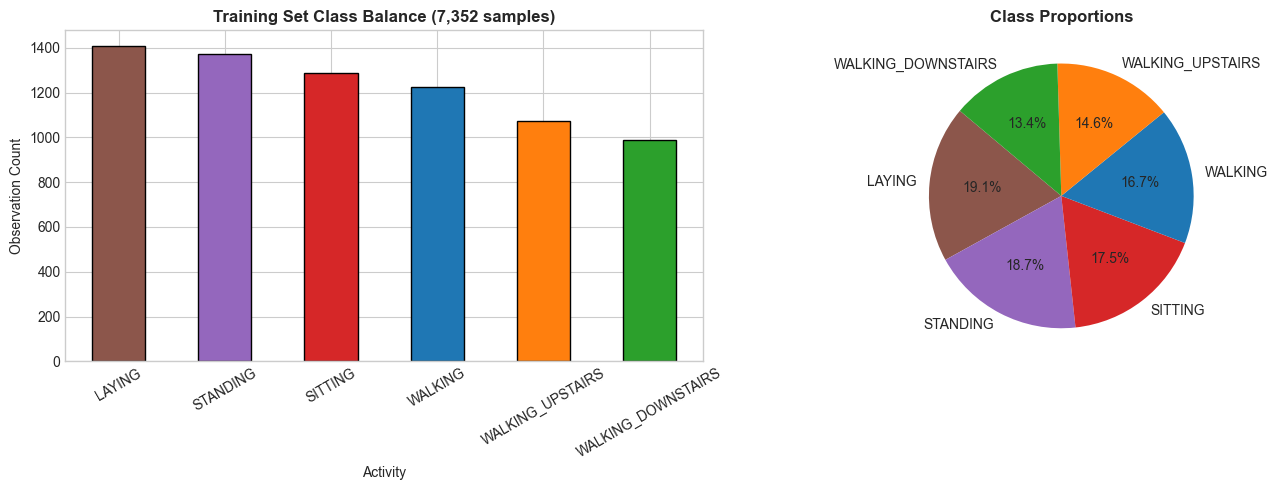

In [3]:
target_col = train_df.columns[-1]
train_counts = train_df[target_col].value_counts()
test_counts = test_df[target_col].value_counts()

summary_dist = pd.DataFrame({
    'Train Samples': train_counts,
    'Train (%)': (train_counts / len(train_df) * 100).round(2),
    'Test Samples': test_counts,
    'Test (%)': (test_counts / len(test_df) * 100).round(2)
})
print(summary_dist)

# High-fidelity visual plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
train_counts.plot(kind='bar', ax=axes[0], color=[palette.get(x, '#333') for x in train_counts.index], edgecolor='black')
axes[0].set_title('Training Set Class Balance (7,352 samples)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Observation Count')
axes[0].tick_params(axis='x', rotation=30)

axes[1].pie(train_counts.values, labels=train_counts.index, autopct='%1.1f%%',
           colors=[palette.get(x, '#333') for x in train_counts.index], startangle=140)
axes[1].set_title('Class Proportions', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('../presentation/01_class_distribution.png', dpi=200)
plt.show()

## 4️⃣ Sensor Feature Anatomy (Time vs Frequency Domain)

📡 FEATURE TAXONOMY BREAKDOWN
Time-Domain Features (prefix 't')       : 265
Frequency-Domain Features (prefix 'f')  : 289
Accelerometer Derived Features          : 345
Gyroscope Derived Features              : 213
Total Multi-axial Engineered Features   : 562


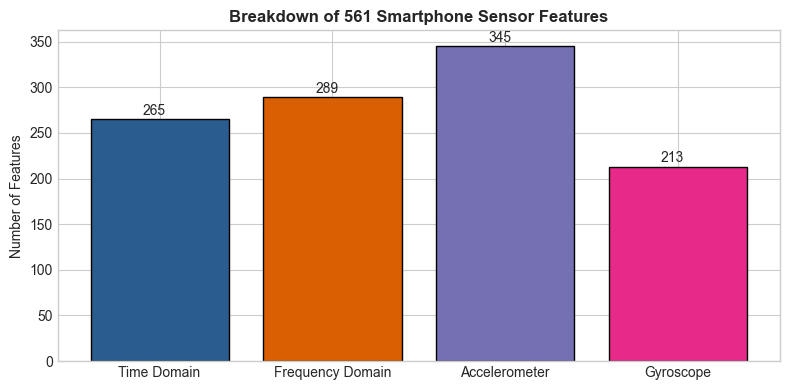

In [4]:
# Dissect feature space
features = [c for c in train_df.columns if c != target_col]
time_domain = [f for f in features if f.startswith('t')]
freq_domain = [f for f in features if f.startswith('f')]
acc_features = [f for f in features if 'Acc' in f]
gyro_features = [f for f in features if 'Gyro' in f]

print("=" * 50)
print("📡 FEATURE TAXONOMY BREAKDOWN")
print("=" * 50)
print(f"Time-Domain Features (prefix 't')       : {len(time_domain)}")
print(f"Frequency-Domain Features (prefix 'f')  : {len(freq_domain)}")
print(f"Accelerometer Derived Features          : {len(acc_features)}")
print(f"Gyroscope Derived Features              : {len(gyro_features)}")
print(f"Total Multi-axial Engineered Features   : {len(features)}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(['Time Domain', 'Frequency Domain', 'Accelerometer', 'Gyroscope'], 
       [len(time_domain), len(freq_domain), len(acc_features), len(gyro_features)],
       color=['#2b5c8f', '#d95f02', '#7570b3', '#e7298a'], edgecolor='black')
ax.set_ylabel('Number of Features')
ax.set_title('Breakdown of 561 Smartphone Sensor Features', fontweight='bold')
for p in ax.patches:
    ax.annotate(str(p.get_height()), (p.get_x() + 0.3, p.get_height() + 5))
plt.tight_layout()
plt.savefig('../presentation/02_feature_breakdown.png', dpi=200)
plt.show()

## 5️⃣ Static vs Dynamic Activity Discrimination
Human activities exhibit a fundamental binary separation:
- **Dynamic Activities**: Walking, Walking Upstairs, Walking Downstairs (high acceleration variance)
- **Static Activities**: Sitting, Standing, Laying (gravitational baseline dominant)

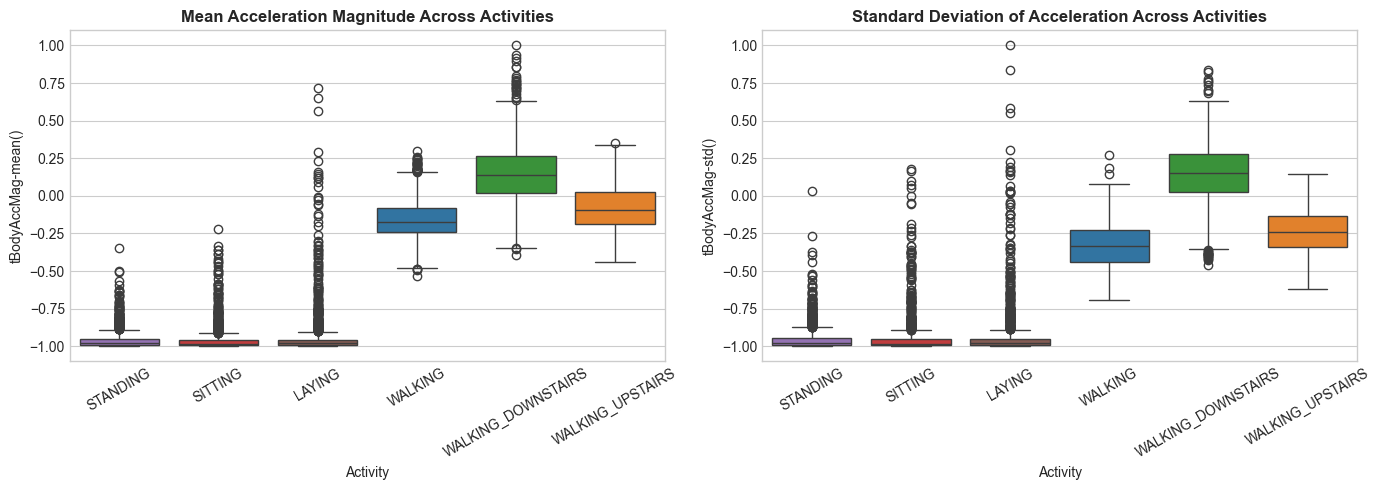

In [5]:
# Compare total acceleration magnitude between static and dynamic
t_acc_mag_mean = 'tBodyAccMag-mean()'
t_acc_mag_std = 'tBodyAccMag-std()'

if t_acc_mag_mean not in train_df.columns:
    # Fallback to first available mean
    t_acc_mag_mean = train_df.columns[0]
    t_acc_mag_std = train_df.columns[1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=train_df, x=target_col, y=t_acc_mag_mean, ax=axes[0], palette=palette)
axes[0].set_title(f'Mean Acceleration Magnitude Across Activities', fontweight='bold')
axes[0].tick_params(axis='x', rotation=30)

sns.boxplot(data=train_df, x=target_col, y=t_acc_mag_std, ax=axes[1], palette=palette)
axes[1].set_title(f'Standard Deviation of Acceleration Across Activities', fontweight='bold')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('../presentation/03_dynamic_vs_static.png', dpi=200)
plt.show()

## 6️⃣ Dimensionality Reduction Preview via PCA (2D & 3D Projections)

PC1 Explained Variance: 50.69%
PC2 Explained Variance: 6.57%
Top 10 PCs Variance   : 70.70%
Top 50 PCs Variance   : 87.42%


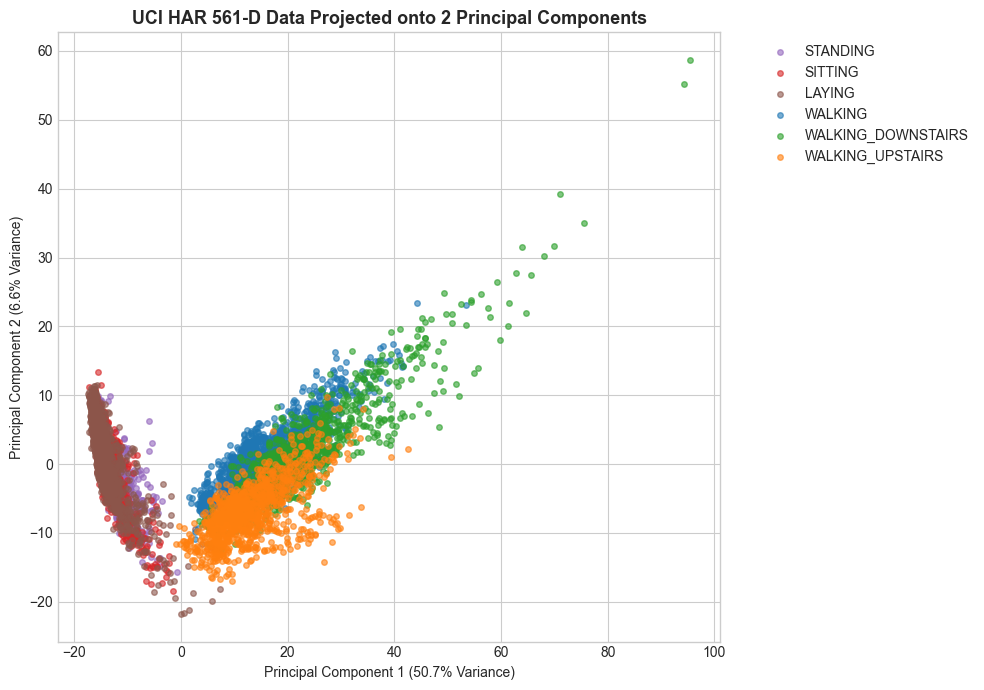

In [6]:
# Extract numerical features
X_train = train_df[features]
y_train = train_df[target_col]
X_test = test_df[features]
y_test = test_df[target_col]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)

# Perform PCA
pca = PCA(n_components=50, random_state=42)
X_pca = pca.fit_transform(X_scaled)
cumsum = np.cumsum(pca.explained_variance_ratio_)

print(f"PC1 Explained Variance: {pca.explained_variance_ratio_[0]*100:.2f}%")
print(f"PC2 Explained Variance: {pca.explained_variance_ratio_[1]*100:.2f}%")
print(f"Top 10 PCs Variance   : {cumsum[9]*100:.2f}%")
print(f"Top 50 PCs Variance   : {cumsum[-1]*100:.2f}%")

# Visualizing 2D latent space
plt.figure(figsize=(10, 7))
for act in y_train.unique():
    mask = (y_train == act)
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], label=act, color=palette.get(act, '#333'), alpha=0.6, s=16)

plt.title(f'UCI HAR 561-D Data Projected onto 2 Principal Components', fontsize=13, fontweight='bold')
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('../presentation/04_pca_latent_space.png', dpi=200)
plt.show()

## 7️⃣ Correlation Matrix & Multicollinearity Inspection

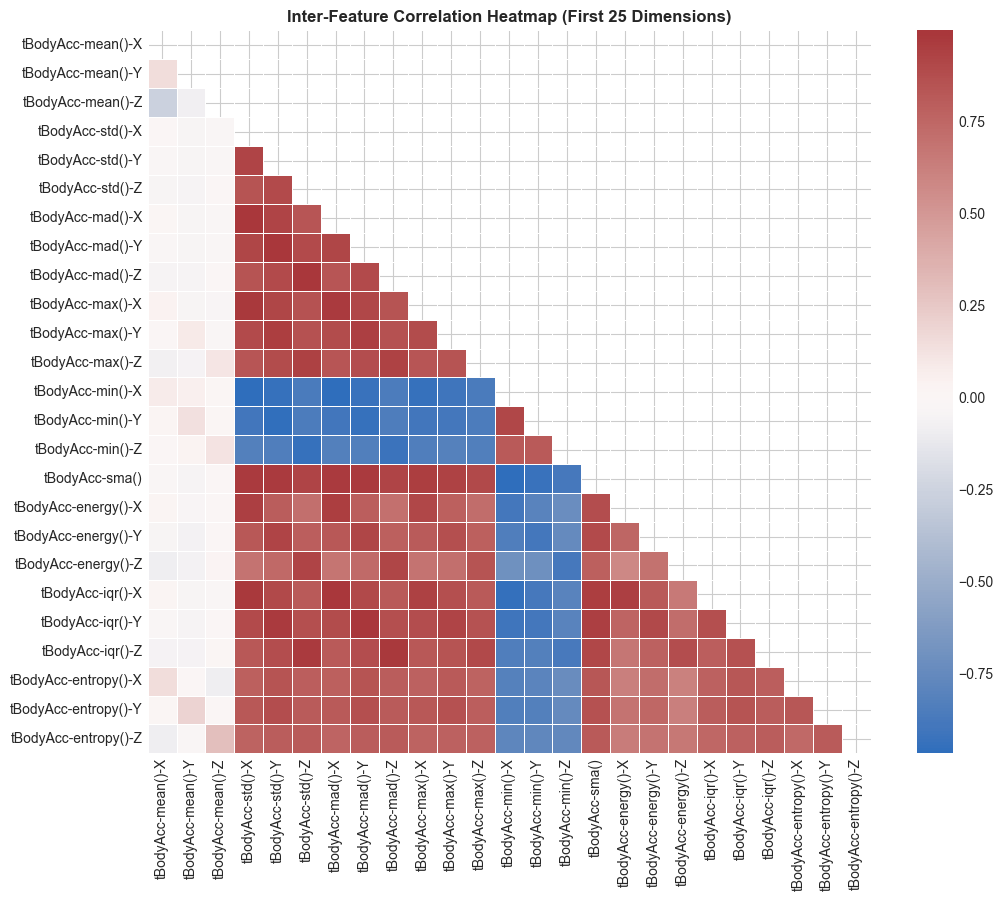

In [7]:
# Sample prominent features for correlation analysis
sample_cols = features[:25]
corr = train_df[sample_cols].corr()

plt.figure(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='vlag', center=0, annot=False, square=True, linewidths=0.5)
plt.title('Inter-Feature Correlation Heatmap (First 25 Dimensions)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('../presentation/05_correlation_heatmap.png', dpi=200)
plt.show()

## 8️⃣ Serialization of Preprocessed Partitions

In [8]:
# Save clean objects for subsequent notebook execution
joblib.dump((X_train, y_train, X_test, y_test), '../data/processed_data.pkl')
print("=" * 60)
print("💾 ARTIFACTS PERSISTENCE SUCCESSFUL")
print("=" * 60)
print("Saved path: ../data/processed_data.pkl")
print("Status: Pipeline ready for Notebook 02 (Clustering: K-Means & DBSCAN).")

💾 ARTIFACTS PERSISTENCE SUCCESSFUL
Saved path: ../data/processed_data.pkl
Status: Pipeline ready for Notebook 02 (Clustering: K-Means & DBSCAN).
